In [4]:
# Jupyter notebook script: evaluate random-convergence clustering results
# - loads one or many CSV result files produced by your pipeline
# - computes convergence of mean/median/quantiles vs #random draws
# - estimates uncertainty (bootstrap CI)
# - answers: "is 20 random sets enough?" via concrete stability criteria
#
# Assumptions about CSV columns (from our script):
#   gene_set in {"random","HVG","Top_MI"}
#   iteration (0..n_random-1 for random; NaN for baselines)
#   accuracy, jaccard
#   seed (optional but present in our output), n_genes, etc.

import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# -----------------------------
# 0) Point this to your new dir
# -----------------------------
RESULT_DIR = "/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/calc_files/MI/clustering_on_MI_genes/testing_number_of_random_gene_sets/"
PATTERN = "*.csv"  # or something like "treutlein_random_convergence*.csv"

files = sorted(glob.glob(os.path.join(RESULT_DIR, PATTERN)))
print(f"Found {len(files)} files")
files[:5]

df_all = pd.concat([pd.read_csv(f).assign(source_file=os.path.basename(f)) for f in files], ignore_index=True)

df_rand = df_all[df_all["gene_set"] == "random"].copy()
df_base = df_all[df_all["gene_set"].isin(["HVG", "Top_MI"])].copy()

df_rand["iteration"] = df_rand["iteration"].astype(int)
print(df_all["gene_set"].value_counts(dropna=False))

Found 3 files
random    1700
HVG          3
Top_MI       3
Name: gene_set, dtype: int64


In [5]:
# -----------------------------
# Helpers (Jaccard-only)
# -----------------------------
def running_mean_curve(df_seed, metric="jaccard"):
    d = df_seed.sort_values("iteration")[metric].to_numpy()
    ks = np.arange(1, len(d) + 1)
    run_mean = np.array([np.mean(d[:k]) for k in ks])
    return pd.DataFrame({"k": ks, "run_mean": run_mean}).set_index("k")


def aggregate_running_mean_across_seeds(df_rand, metric="jaccard"):
    seeds = sorted(df_rand["seed"].dropna().unique().tolist())
    if len(seeds) == 0:
        raise ValueError("No 'seed' column values found in random rows. Did you run with --seed?")

    curves = []
    for s in seeds:
        d = df_rand[df_rand["seed"] == s]
        c = running_mean_curve(d, metric=metric)
        c = c.rename(columns={"run_mean": f"seed_{int(s)}"})
        curves.append(c)

    mat = pd.concat(curves, axis=1).sort_index()

    mean_k = mat.mean(axis=1, skipna=True)
    lo_k = mat.quantile(0.025, axis=1, interpolation="linear")
    hi_k = mat.quantile(0.975, axis=1, interpolation="linear")

    out = pd.DataFrame({"mean": mean_k, "lo": lo_k, "hi": hi_k})
    out.index.name = "k"
    return out


def get_baseline_mean(df_base, gene_set, metric="jaccard"):
    vals = df_base[df_base["gene_set"] == gene_set][metric].dropna().values
    return float(np.mean(vals)) if len(vals) else np.nan


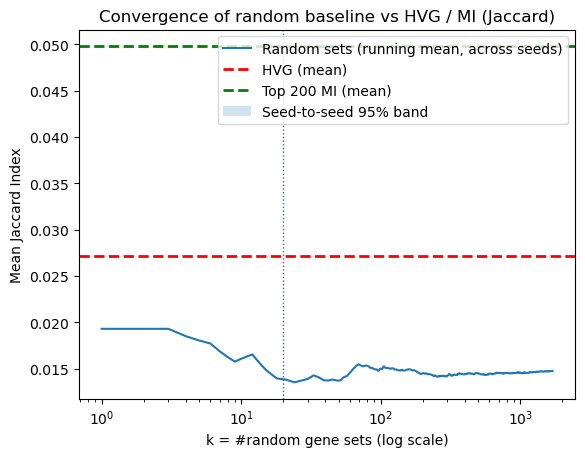

HVG mean Jaccard: 0.027163807585441
Top_MI mean Jaccard: 0.0497811516307636


In [13]:
# -----------------------------
# Aggregate convergence plot (Jaccard)
# - x axis log scale
# - add HVG + Top_MI horizontal lines
# -----------------------------
agg = aggregate_running_mean_across_seeds(df_rand, metric="jaccard")

hvg_mean = get_baseline_mean(df_base, "HVG", metric="jaccard")
mi_mean  = get_baseline_mean(df_base, "Top_MI", metric="jaccard")

plt.figure()
plt.plot(agg.index, agg["mean"], label="Random sets (running mean, across seeds)")
plt.fill_between(agg.index, agg["lo"], agg["hi"], alpha=0.2, label="Seed-to-seed 95% band")

# baselines as horizontal lines (mean across files/seeds)
if np.isfinite(hvg_mean):
    plt.axhline(hvg_mean, linewidth=2, color = "r", linestyle="--", label="HVG (mean)")
if np.isfinite(mi_mean):
    plt.axhline(mi_mean, linewidth=2, color = "g", linestyle="--", label="Top 200 MI (mean)")

# mark k=20
plt.axvline(20, linestyle=":", linewidth=1)

plt.xscale("log")
plt.xlabel("k = #random gene sets (log scale)")
plt.ylabel("Mean Jaccard Index")
plt.title("Convergence of random baseline vs HVG / MI (Jaccard)")
plt.legend()
plt.savefig("jaccard_index_with_more_random_samples_treutlein.pdf", bbox_inches = "tight")
plt.show()

print(f"HVG mean Jaccard: {hvg_mean}")
print(f"Top_MI mean Jaccard: {mi_mean}")


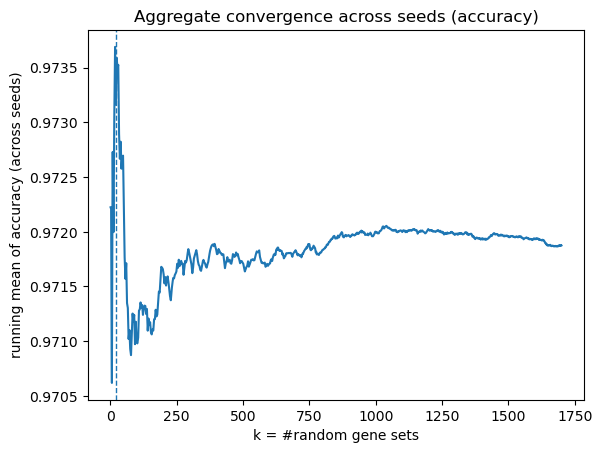

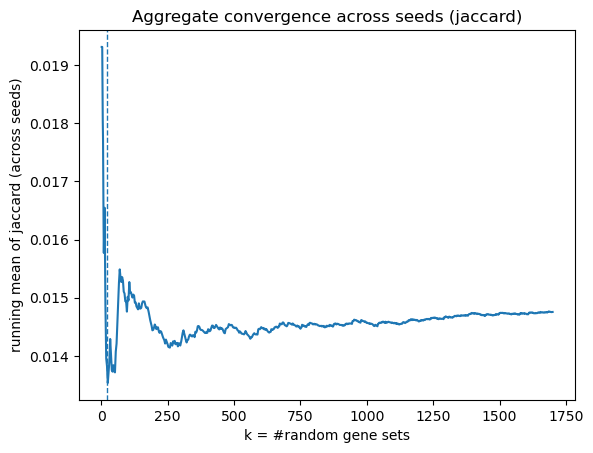

In [16]:
# -----------------------------
# 5) Aggregate convergence across seeds (mean ± CI across seeds)
# -----------------------------
def aggregate_convergence_across_seeds(metric="accuracy"):
    seeds = sorted(df_rand["seed"].dropna().unique().tolist())
    # compute running mean curves for each seed, then align by k
    curves = []
    for s in seeds:
        d = df_rand[df_rand["seed"] == s]
        rs = running_stats_one_seed(d, metric=metric)[["k", "run_mean"]].copy()
        rs = rs.rename(columns={"run_mean": f"seed_{int(s)}"}).set_index("k")
        curves.append(rs)

    if not curves:
        raise ValueError("No seeds found in df_rand.")

    mat = pd.concat(curves, axis=1).sort_index()
    # mean across seeds at each k
    mean_k = mat.mean(axis=1, skipna=True)
    # 2.5/97.5 quantiles across seeds (not bootstrap, but seed-to-seed variability)
    lo_k = mat.quantile(0.025, axis=1, interpolation="linear")
    hi_k = mat.quantile(0.975, axis=1, interpolation="linear")

    out = pd.DataFrame({"mean": mean_k, "lo": lo_k, "hi": hi_k})
    out.index.name = "k"
    return out

def plot_aggregate(metric="accuracy"):
    agg = aggregate_convergence_across_seeds(metric=metric)
    plt.figure()
    plt.plot(agg.index, agg["mean"])
    plt.fill_between(agg.index, agg["lo"], agg["hi"], alpha=0.2)
    plt.axvline(20, linestyle="--", linewidth=1)
    plt.xlabel("k = #random gene sets")
    plt.ylabel(f"running mean of {metric} (across seeds)")
    plt.title(f"Aggregate convergence across seeds ({metric})")
    plt.show()
    return agg

agg_acc = plot_aggregate("accuracy")
agg_jac = plot_aggregate("jaccard")
